<a href="https://colab.research.google.com/github/rach-horsman/skills-introduction-to-github/blob/main/polynomialregression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/500
2/2 [==============================] - 0s 10ms/step - loss: 0.4665
Epoch 2/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4649
Epoch 3/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4632
Epoch 4/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4616
Epoch 5/500
2/2 [==============================] - 0s 10ms/step - loss: 0.4600
Epoch 6/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4586
Epoch 7/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4568
Epoch 8/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4553
Epoch 9/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4538
Epoch 10/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4524
Epoch 11/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4508
Epoch 12/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4491
Epoch 13/500
2/2 [==============================] - 0s 8ms/

2/2 [==============================] - 0s 9ms/step
Epoch 1/500
2/2 [==============================] - 0s 10ms/step - loss: 0.4763
Epoch 2/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4721
Epoch 3/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4672
Epoch 4/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4631
Epoch 5/500
2/2 [==============================] - 0s 9ms/step - loss: 0.4586
Epoch 6/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4542
Epoch 7/500
2/2 [==============================] - 0s 7ms/step - loss: 0.4505
Epoch 8/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4460
Epoch 9/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4420
Epoch 10/500
2/2 [==============================] - 0s 7ms/step - loss: 0.4377
Epoch 11/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4338
Epoch 12/500
2/2 [==============================] - 0s 8ms/step - loss: 0.4298
Epoch 13/

2/2 [==============================] - 0s 7ms/step


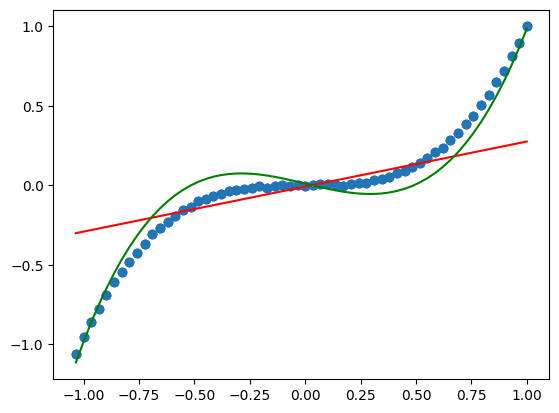

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import PolynomialFeatures

# generate data - some element of randomness with use of np.random.randn
def generate_data():
    X = np.arange(-30, 30, 1)
    y = 9*X**3 + 5*X**2 + np.random.randn(60)*1000
    return X, y
trX, trY = generate_data()

# scale data so in both axis ranges from -1 to 1 otherwise values mean the training takes too long
trX = trX/max(trX)
trY = trY/max(trY)

# plot the generated data
fig, ax = plt.subplots()
ax.scatter(trX, trY, c='blue')

# set magnitude of polynomila here
n = 3

# identify additional polynomial characteristics
# returns: [1, x, x^2, x^3]

trX_expanded = np.expand_dims(trX, axis=1)
poly = PolynomialFeatures(n)
trX_expanded = poly.fit_transform(trX_expanded)

# setting up a linear model
inp = Input((1))
out = Dense(1)(inp)
model_linear = Model(inputs=inp, outputs=out)
model_linear.compile(
optimizer=Adam(learning_rate=1e-3),
loss="mean_squared_error")

# train the model and plot result
model_linear.fit(trX, trY, epochs=500)
# ax.scatter(trX, trY)
ax.plot(trX, model_linear.predict(trX), color="red")


# setting up a polynomial model of order n
#since one of the features is 1, we need an extra input
inp = Input((n+1))
out = Dense(1)(inp)
model = Model(inputs=inp, outputs=out)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="mean_squared_error")

# train the model and plot result
model.fit(trX_expanded, trY, epochs=500)
ax.scatter(trX, trY)
ax.plot(trX, model.predict(trX_expanded), color="green")

#print(model.predict([0.0]))